In [1]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
from random import shuffle

In [2]:
r_scape = pickle.load(open("data/eval_rscape.pickle", "rb"))
phylo_score = pickle.load(open("data/eval_phyloscore.pickle", "rb"))
datasets = list(map(str.strip, open("3d.txt", "r")))

In [3]:
def extract_hyperparameters(dict):
    keys = [k[1:] for k in dict.keys()]
    return set(keys)

In [4]:
def best_hyper(dict, train_set):
    best_score = -1
    best_hyperparameters = None
    for hyper in extract_hyperparameters(dict):
        score = 0
        for dataset in train_set:
            score += dict[(dataset, *hyper)][1]
        
        if score > best_score:
            best_score = score
            best_hyperparameters = hyper
    return best_hyperparameters

In [5]:
best_hyper(phylo_score, datasets)

('0.5', '0.01', 'optdiff', 'APC')

In [6]:
def cross_validation(data, per_dataset_results : dict, splits=5):
    local_datasets = list(datasets)
    # shuffle the datasets
    shuffle(local_datasets)

    #split in splits folds
    numpy = np.array(local_datasets)
    folds = np.array_split(numpy, splits)

    results = []
    for i in range(splits):
        test = set(folds[i])
        train = set(numpy) - test

        best_hyperparameters = best_hyper(data, train)
        print(f"Best hyperparameters for fold {i}: {best_hyperparameters}")
        print("RF00026" in test)
        for dataset in test:
            results.append(data[(dataset, *best_hyperparameters)][1])
            if dataset not in per_dataset_results:
                per_dataset_results[dataset] = []
            per_dataset_results[dataset].append(data[(dataset, *best_hyperparameters)][1])
        
    return np.mean(results) * 100

In [7]:
rscape_per_dataset = {}
phylo_score_per_dataset = {}
results_rscape = [cross_validation(r_scape, rscape_per_dataset) for _ in range(1)]
results_phyloscore = [cross_validation(phylo_score, phylo_score_per_dataset) for _ in range(1000)]

Best hyperparameters for fold 0: ('GTp',)
True
Best hyperparameters for fold 1: ('GTp',)
False
Best hyperparameters for fold 2: ('GTp',)
False
Best hyperparameters for fold 3: ('GTp',)
False
Best hyperparameters for fold 4: ('GTp',)
False
Best hyperparameters for fold 0: ('0.5', '0.01', 'optdiff', 'ASC')
False
Best hyperparameters for fold 1: ('0.5', '0.01', 'optdiff', 'APC')
False
Best hyperparameters for fold 2: ('0.5', '0.01', 'optdiff', 'APC')
True
Best hyperparameters for fold 3: ('0.5', '0.01', 'optdiff', 'APC')
False
Best hyperparameters for fold 4: ('0.5', '0.0', 'optdiff', 'ASC')
False
Best hyperparameters for fold 0: ('0.5', '0.1', 'optdiff', 'APC')
False
Best hyperparameters for fold 1: ('0.5', '0.01', 'optdiff', 'ASC')
False
Best hyperparameters for fold 2: ('0.5', '0.01', 'optdiff', 'ASC')
True
Best hyperparameters for fold 3: ('0.5', '0.01', 'optdiff', 'ASC')
False
Best hyperparameters for fold 4: ('0.5', '0.01', 'optdiff', 'APC')
False
Best hyperparameters for fold 0: ('

In [8]:
def plot_side_by_side_barplot(dict1, dict2, label1='Dataset 1', label2='Dataset 2', 
                               error_type='std', figsize=(12, 6)):
    """
    Create side-by-side bar plot comparing two dictionaries.
    
    Parameters:
    -----------
    dict1, dict2 : dict
        Dictionaries with keys as categories and values as lists of floats
    label1, label2 : str
        Labels for the two datasets
    figsize : tuple
        Figure size (width, height)
    """
    # Get common categories (keys present in both dictionaries)
    categories = sorted(set(dict1.keys()) | set(dict2.keys()))
    
    # Calculate statistics for dict1
    means1 = []
    errors1 = []
    for cat in categories:
        data = dict1[cat]
        means1.append(np.mean(data))
        errors1.append(np.std(data))
    
    means2 = []
    errors2 = []
    for cat in categories:
        data = dict2[cat]
        means2.append(np.mean(data))
        errors2.append(np.std(data))    
    
    
    # Create plot
    x = np.arange(len(categories))
    width = 0.35
    
    fig, ax = plt.subplots(figsize=figsize)
    
    # Create bars
    bars1 = ax.bar(x - width/2, means1, width, yerr=errors1, 
                   capsize=2, label=label1, color='skyblue', 
                   edgecolor='black', alpha=0.7)
                   
    bars2 = ax.bar(x + width/2, means2, width, yerr=errors2, 
                   capsize=2, label=label2, color='red', 
                   edgecolor='black', alpha=0.7)
    
    # Customize plot
    ax.set_xlabel('Categories', fontsize=12)
    ax.set_ylabel('Values', fontsize=12)
    ax.set_title(f'Side-by-Side Comparison: {label1} vs {label2}', fontsize=14)
    ax.set_xticks(x)
    ax.set_xticklabels(categories, rotation=90)
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    return fig, ax

In [9]:
def scatter_compare_with_diagonal(dict1, dict2, label1='Dataset 1', label2='Dataset 2',
                                   error_type='sem', figsize=(8, 8)):
    """
    Create scatter plot comparing two dictionaries with diagonal line.
    
    Parameters:
    -----------
    dict1, dict2 : dict
        Dictionaries with same keys and lists of floats as values
    label1, label2 : str
        Labels for axes
    error_type : str or None
        'std', 'sem', 'ci95', or None for error bars
    figsize : tuple
        Figure size (square recommended)
    """
    # Get common categories
    common_keys = sorted(set(dict1.keys()) & set(dict2.keys()))
    
    if not common_keys:
        raise ValueError("Dictionaries have no common keys")
    
    # Calculate means and errors
    medians1 = []
    medians2 = []
    errors1 = []
    errors2 = []
    
    for key in common_keys:
        data1 = dict1[key]
        data2 = dict2[key]
        
        median1 = np.median(data1)
        median2 = np.median(data2)
        medians1.append(median1)
        medians2.append(median2)
        
        if error_type == 'std':
            errors1.append(np.std(data1))
            errors2.append(np.std(data2))
        elif error_type == 'minmax':
            errors1.append([np.abs(np.median(data1) - np.min(data1)), np.abs(np.max(data1) - np.median(data1))])
            errors2.append([np.abs(np.median(data2) - np.min(data2)), np.abs(np.max(data2) - np.median(data2))])
        elif error_type == 'ci95':
            sem1 = np.std(data1) / np.sqrt(len(data1))
            sem2 = np.std(data2) / np.sqrt(len(data2))
            errors1.append(sem1 * 1.96)
            errors2.append(sem2 * 1.96)
        else:
            errors1.append(0)
            errors2.append(0)
    
    # Create plot
    fig, ax = plt.subplots(figsize=figsize)
    
    # Add diagonal line (y=x)
    min_val = 0
    max_val = 1
    ax.plot([min_val, max_val], 
            [min_val, max_val], 
            'k--', alpha=0.5)
    
    # Add error bars (horizontal and vertical)
    if error_type:
        ax.errorbar(medians1, medians2,
                   yerr=np.array(errors2).T,
                   fmt='o', capsize=3, capthick=1, elinewidth=1,
                   color='blue', alpha=0.7, markersize=2,
                   label=f'{label1} vs {label2}')
    else:
        ax.scatter(medians1, medians2, color='blue', alpha=0.7, s=80,
                  label=f'{label1} vs {label2}')
    
    # Customize plot
    ax.set_xlabel(f'{label1} (Average Precision)', fontsize=12)
    ax.set_ylabel(f'{label2} (Average Precision)', fontsize=12)
    ax.set_title(f'Scatter Plot Comparison: {label1} vs {label2}', fontsize=14)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best')
    ax.set_aspect('equal')
    
    plt.tight_layout()
    return fig, ax

(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Scatter Plot Comparison: R-scape vs PhyloScore'}, xlabel='R-scape (Average Precision)', ylabel='PhyloScore (Average Precision)'>)

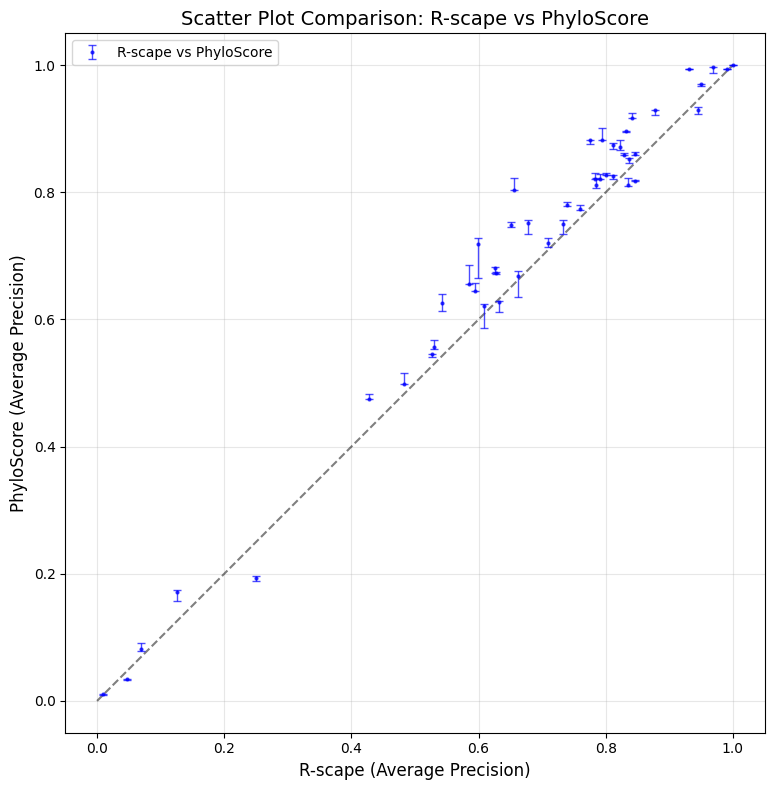

In [10]:
scatter_compare_with_diagonal(rscape_per_dataset, phylo_score_per_dataset, label1='R-scape', label2='PhyloScore', error_type='minmax')

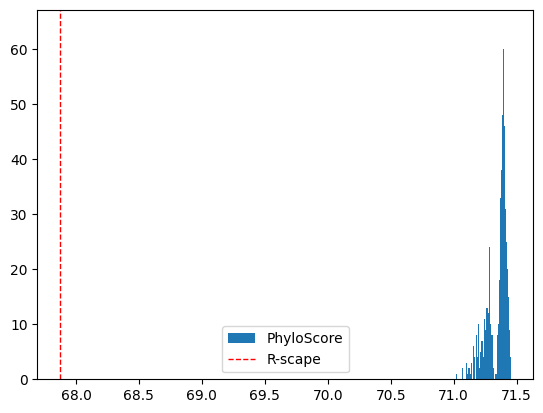

In [11]:
plt.hist(results_phyloscore, bins=100, label='PhyloScore')
#plot a line where rscape performance is
plt.axvline(np.mean(results_rscape), color='red', linestyle='dashed', linewidth=1, label='R-scape')
plt.legend()

In [116]:
results_rscape

[np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.87249395707249),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.87249395707249),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.87249395707249),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.f

In [117]:
results_phyloscore

[np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.1930575766524),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.25114344126864),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002381),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.25177726007168),
 np.float

In [99]:
np.mean([r_scape[(dataset, "GTp")][1] for dataset in datasets]) * 100

np.float64(67.8724939570725)

In [125]:
np.mean([phylo_score[(dataset, '0.5', '0.01', "optdiff", "APC")][1] for dataset in datasets]) * 100

np.float64(71.47547338347354)

In [ ]:

sort_scores = np.sort(scores)

L = reverse_triangle_number(len(scores)) + 1

# Remove L//2 highest scores, because they might be positive
sort_scores = sort_scores[:-(L // 2)]


fit = scipy.stats.gamma.fit(sort_scores, method='mm')